In [1]:
%pip install pandas numpy matplotlib seaborn scikit-surprise

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.3 MB 722.6 kB/s eta 0:00:02
   --------------- ------------------------ 0.5/1.3 MB 722.6 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.3 MB 856.9 kB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.3 MB 856.9 kB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.3 MB 856.9 kB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 615.6 kB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 615.6 kB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 660.7 kB/s  0:00:01

   ---------------------------------------- 0/2 [scikit-surprise]
   ---------------------------------------- 0/2 [scikit-surprise]
   ---------------------------------------- 0/2 [scikit-surprise]
   ---------------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from surprise import Dataset, Reader, SVD
from surprise import accuracy
from surprise.model_selection import train_test_split

DATA_DIR = Path.cwd()

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
books = pd.read_csv(DATA_DIR / "books.csv")
book_tags = pd.read_csv(DATA_DIR / "book_tags.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
to_read = pd.read_csv(DATA_DIR / "to_read.csv")

print("Ratings shape:", ratings.shape)
print("Books shape:", books.shape)
print("Book tags shape:", book_tags.shape)
print("Tags shape:", tags.shape)
print("To-read shape:", to_read.shape)

display(ratings.head())
display(books.head())

Ratings shape: (981756, 3)
Books shape: (10000, 23)
Book tags shape: (999912, 3)
Tags shape: (34252, 2)
To-read shape: (912705, 2)


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [3]:
print("Rating columns:", ratings.columns.tolist())
print("Book columns:", books.columns.tolist())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nUnique users:", ratings["user_id"].nunique())
print("Unique books rated:", ratings["book_id"].nunique())
print("Unique books in metadata:", books["book_id"].nunique())

Rating columns: ['book_id', 'user_id', 'rating']
Book columns: ['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']

Missing values in ratings:
book_id    0
user_id    0
rating     0
dtype: int64

Rating distribution:
rating
1     19575
2     63231
3    248623
4    357366
5    292961
Name: count, dtype: int64

Unique users: 53424
Unique books rated: 10000
Unique books in metadata: 10000


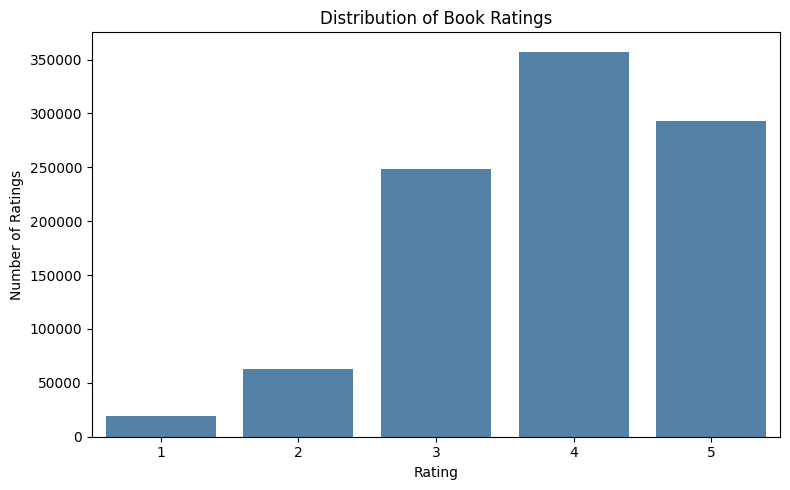

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating",
    color="steelblue"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

In [5]:
ratings = ratings.dropna(
    subset=["user_id", "book_id", "rating"]
).copy()

ratings["user_id"] = ratings["user_id"].astype(str)
ratings["book_id"] = ratings["book_id"].astype(str)

reader = Reader(rating_scale=(1, 5))

dataset = Dataset.load_from_df(
    ratings[["user_id", "book_id", "rating"]],
    reader
)

trainset, testset = train_test_split(
    dataset,
    test_size=0.2,
    random_state=42
)

print("Training ratings:", trainset.n_ratings)
print("Testing ratings:", len(testset))

Training ratings: 785404
Testing ratings: 196352


In [6]:
svd_model = SVD(
    n_factors=100,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

svd_model.fit(trainset)

print("SVD model training completed.")

SVD model training completed.


In [7]:
predictions = svd_model.test(testset)

rmse = accuracy.rmse(predictions, verbose=True)
mae = accuracy.mae(predictions, verbose=True)

print(f"Final RMSE: {rmse:.4f}")
print(f"Final MAE: {mae:.4f}")

RMSE: 0.8435
MAE:  0.6595
Final RMSE: 0.8435
Final MAE: 0.6595


In [8]:
def recommend_books(user_id, n=10):
    user_id = str(user_id)

    if user_id not in trainset._raw2inner_id_users:
        raise ValueError(
            "This user was not present in the training data."
        )

    rated_books = set(
        ratings.loc[
            ratings["user_id"] == user_id,
            "book_id"
        ].astype(str)
    )

    candidates = books[
        ~books["book_id"].astype(str).isin(rated_books)
    ].copy()

    candidates["predicted_rating"] = candidates[
        "book_id"
    ].astype(str).apply(
        lambda book_id: svd_model.predict(
            user_id, book_id
        ).est
    )

    recommendations = candidates.sort_values(
        "predicted_rating",
        ascending=False
    ).head(n)

    display_columns = [
        col for col in [
            "book_id",
            "title",
            "authors",
            "average_rating",
            "predicted_rating"
        ]
        if col in recommendations.columns
    ]

    return recommendations[display_columns].reset_index(drop=True)

In [9]:
sample_user = ratings["user_id"].iloc[0]

print("Recommendations for user:", sample_user)

recommend_books(sample_user, n=10)

Recommendations for user: 314


,book_id,title,authors,average_rating,predicted_rating
0,2767,A People's History of the United States,Howard Zinn,4.07,4.438535
1,9569,Villa Incognito,Tom Robbins,3.65,4.387310
2,5344,Hard Times,Charles Dickens,3.50,4.377133
3,7455,Sex and the City,Candace Bushnell,3.37,4.320301
4,9566,Still Life with Woodpecker,Tom Robbins,4.04,4.316645
5,4708,The Beautiful and Damned,F. Scott Fitzgerald,3.75,4.305251
6,998,The Millionaire Next Door: The Surprising Secr...,"Thomas J. Stanley, William D. Danko",4.00,4.304020
7,7081,The Android's Dream,John Scalzi,3.97,4.281771
8,3885,The Taste of Home Cookbook,"Janet Briggs, Beth Wittlinger",4.25,4.277941
9,1618,The Curious Incident of the Dog in the Night-Time,Mark Haddon,3.85,4.257310


In [10]:
def precision_recall_at_k(predictions, k=10, threshold=4.0):
    user_predictions = {}

    for uid, iid, true_rating, estimated_rating, _ in predictions:
        user_predictions.setdefault(uid, []).append(
            (iid, true_rating, estimated_rating)
        )

    precisions = []
    recalls = []

    for uid, user_ratings in user_predictions.items():
        user_ratings.sort(
            key=lambda x: x[2],
            reverse=True
        )

        top_k = user_ratings[:k]

        relevant_recommended = sum(
            true_rating >= threshold
            for _, true_rating, _ in top_k
        )

        relevant_total = sum(
            true_rating >= threshold
            for _, true_rating, _ in user_ratings
        )

        precisions.append(
            relevant_recommended / len(top_k)
            if top_k else 0
        )

        recalls.append(
            relevant_recommended / relevant_total
            if relevant_total else 0
        )

    return np.mean(precisions), np.mean(recalls)


precision, recall = precision_recall_at_k(
    predictions,
    k=10,
    threshold=4.0
)

print(f"Precision@10: {precision:.4f}")
print(f"Recall@10: {recall:.4f}")

Precision@10: 0.6766
Recall@10: 0.8223


In [11]:
import joblib
from pathlib import Path

MODEL_PATH = Path.cwd() / "book_svd_model.joblib"

joblib.dump(svd_model, MODEL_PATH)

print(f"Model saved successfully at: {MODEL_PATH}")

Model saved successfully at: d:\Desktop\rc\archive (1)\book_svd_model.joblib
